In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

In [2]:
warnings.filterwarnings('ignore')

np.random.seed(42)

print('Statitical Analysis Environment Ready')

Statitical Analysis Environment Ready


In [3]:
n = 10000

data = pd.DataFrame({
    "Customer_ID":range(1, n+1),
    "Age": np.random.randint(18, 65, n),
    "Order_Value": np.random.normal(25000, 700, n),
    "Units_Purchased": np.random.randint(1, 10, n),
    "Discount": np.random.uniform(0, 40, n),
    "Customer_Rating": np.random.randint(1, 6, n),
    "Category": np.random.choice(
        ['Electronics', 'Fashion', 'Grocery', 'Home'],
        n
    )
})

In [4]:
data

,Customer_ID,Age,Order_Value,Units_Purchased,Discount,Customer_Rating,Category
0,1,56,23897.991856,5,30.433674,2,Electronics
1,2,46,24299.578333,3,18.298186,4,Fashion
2,3,32,24872.854147,7,7.036917,1,Grocery
3,4,60,25404.811597,4,18.594898,1,Fashion
4,5,25,24395.151034,6,25.915490,5,Electronics
...,...,...,...,...,...,...,...
9995,9996,33,25941.537131,9,38.467366,1,Grocery
9996,9997,29,25589.507637,8,24.234992,3,Electronics
9997,9998,18,25086.678956,1,33.220713,5,Grocery
9998,9999,25,24025.418499,1,20.579090,2,Home


In [6]:
print("Dataset Shape:", data.shape)
print("\nNumber of Rows:",data.shape[0])
print("\nNumber of Columns:",data.shape[1])
print("\nColumn Names:")
print(data.columns.tolist())
print("\nData Types:")
print(data.dtypes)

print("\n Missing Values:")
print(data.isnull().sum())

Dataset Shape: (10000, 7)

Number of Rows: 10000

Number of Columns: 7

Column Names:
['Customer_ID', 'Age', 'Order_Value', 'Units_Purchased', 'Discount', 'Customer_Rating', 'Category']

Data Types:
Customer_ID          int64
Age                  int64
Order_Value        float64
Units_Purchased      int64
Discount           float64
Customer_Rating      int64
Category            object
dtype: object

 Missing Values:
Customer_ID        0
Age                0
Order_Value        0
Units_Purchased    0
Discount           0
Customer_Rating    0
Category           0
dtype: int64


In [7]:
numerical_columns = [
    "Age",
    "Order_Value",
    "Units_Purchased",
    "Discount",
    "Customer_Rating"
]

statistics = data[numerical_columns].describe()
display(statistics)

,Age,Order_Value,Units_Purchased,Discount,Customer_Rating
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,41.054000,25000.203989,5.054300,19.911953,3.00410
std,13.484104,697.226877,2.554644,11.525508,1.42439
min,18.000000,22162.164941,1.000000,0.000221,1.00000
25%,30.000000,24521.264975,3.000000,9.867078,2.00000
50%,41.000000,24998.309667,5.000000,19.979183,3.00000
75%,53.000000,25469.456655,7.000000,29.849838,4.00000
max,64.000000,27519.626746,9.000000,39.991575,5.00000


In [8]:
for column in numerical_columns:
  print("\nVariable:",column)
  print("\nMean:",data[column].mean())
  print("\nMedian:",data[column].median())
  print("\nMode:",data[column].mode().tolist())


Variable: Age

Mean: 41.054

Median: 41.0

Mode: [43]

Variable: Order_Value

Mean: 25000.203989293415

Median: 24998.30966729957

Mode: [22162.164940667837, 22368.154751326176, 22613.723283784555, 22760.167606345523, 22777.675743306565, 22826.776323791702, 22829.63717923724, 22854.88019186924, 22867.50283534727, 22868.73648444882, 22893.041243843258, 22940.421911514026, 22948.348131834813, 22961.50593443462, 22978.65598949799, 22994.703075352933, 23000.80752999716, 23003.664511452127, 23008.878645754517, 23010.455186072526, 23021.028991488998, 23026.21988631264, 23029.69971035573, 23035.981006496862, 23040.565707172816, 23054.205179943125, 23064.865165098036, 23065.400322423036, 23087.267960916342, 23091.170349071563, 23105.437079529594, 23106.647141498725, 23117.670239669078, 23118.032290142197, 23133.403420479604, 23133.647462773388, 23163.7950660981, 23185.921119837392, 23195.85848390396, 23196.359163197612, 23201.839384232702, 23203.847902857295, 23206.551921580238, 23209.1984984

In [9]:
for column in numerical_columns:
  print("\nVariable:",column)

  print("Population Variance:",data[column].var(ddof=0))
  print("Sample Variance:",data[column].var(ddof=1))
  print("Population Standard Deviation:",data[column].std(ddof=0))
  print("Sample Standard Deviation:",data[column].std(ddof=1))


Variable: Age
Population Variance: 181.8028839999961
Sample Variance: 181.8210661066068
Population Standard Deviation: 13.483429979051921
Sample Standard Deviation: 13.484104201117951

Variable: Order_Value
Population Variance: 486076.7056723739
Sample Variance: 486125.3182041943
Population Standard Deviation: 697.1920149229866
Sample Standard Deviation: 697.2268771384206

Variable: Units_Purchased
Population Variance: 6.525551510000232
Sample Variance: 6.526204130413274
Population Standard Deviation: 2.554515905215748
Sample Standard Deviation: 2.554643640591242

Variable: Discount
Population Variance: 132.82406244251723
Sample Variance: 132.83734617713495
Population Standard Deviation: 11.524932209888144
Sample Standard Deviation: 11.525508499720736

Variable: Customer_Rating
Population Variance: 2.0286831899999345
Sample Variance: 2.028886078607795
Population Standard Deviation: 1.4243185001957723
Sample Standard Deviation: 1.4243897214624215


ddof=0: Population variance and standard deviation.


ddof=1: Sample variance and standard deviation.

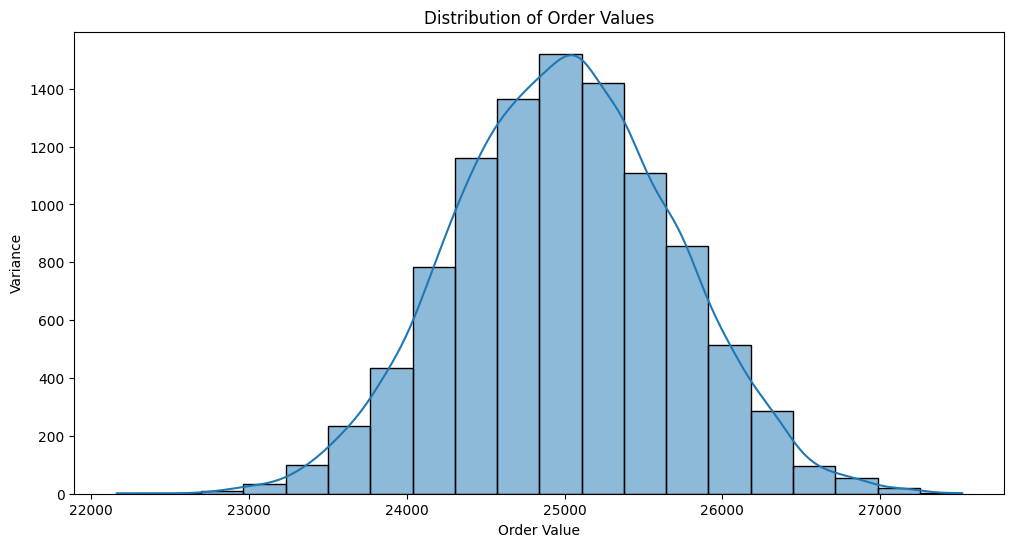

In [10]:
plt.figure(figsize=(12,6))

sns.histplot(
    data['Order_Value'],
    bins=20,
    kde = True
)

plt.title("Distribution of Order Values")
plt.xlabel("Order Value")
plt.ylabel("Variance")
plt.show()

Interpretation questions:
- Are most customer transactions concentrated around the mean?
- Is the distribution symmetric?
- Are there unusually high transactions?
- Is the standard deviation large relative to the mean?

In [11]:
percentiles = [10, 20, 25, 30, 40, 50, 60, 70, 75, 80, 90, 95, 99]

for p in percentiles:
  value = np.percentile(data['Order_Value'],p)
  print(f"{p}th percentile:{value:2f}")

10th percentile:24114.953405
20th percentile:24406.587422
25th percentile:24521.264975
30th percentile:24625.054749
40th percentile:24816.783616
50th percentile:24998.309667
60th percentile:25170.977542
70th percentile:25365.290447
75th percentile:25469.456655
80th percentile:25598.898918
90th percentile:25895.981489
95th percentile:26147.959039
99th percentile:26625.451117


In [12]:
Q1 = data['Order_Value'].quantile(0.25)
Q2 = data['Order_Value'].quantile(0.50)
Q3 = data['Order_Value'].quantile(0.75)

print("Q1:",Q1)
print("Q2:",Q2)
print("Q3:",Q3)

Q1: 24521.26497452864
Q2: 24998.30966729957
Q3: 25469.45665467966


Interpretation:
- Q1: Approximately 25% of observations are at or below this value.
- Q2: Approximately 50% of observations are at or below this value.
- Q3: Approximately 75% of observations are at or below this value.

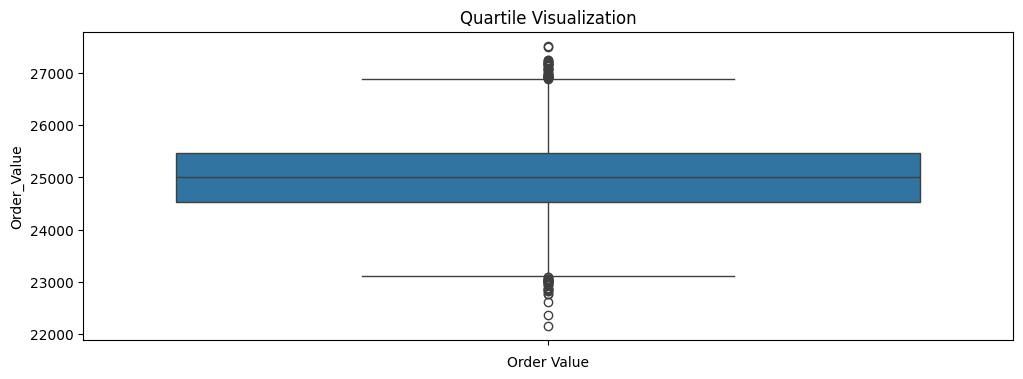

In [13]:
plt.figure(figsize=(12,4))

sns.boxplot(data['Order_Value'])

plt.title("Quartile Visualization")
plt.xlabel("Order Value")
plt.show()

In [14]:
Q1 = data['Order_Value'].quantile(0.25)
Q3 = data['Order_Value'].quantile(0.75)

IQR = Q3 - Q1

print("Q1:",Q1)
print("Q3:",Q3)
print("IQR:",IQR)

Q1: 24521.26497452864
Q3: 25469.45665467966
IQR: 948.1916801510197


In [15]:
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

print("Lower Fence:",lower_fence)
print("Upper Fence:",upper_fence)

Lower Fence: 23098.977454302112
Upper Fence: 26891.74417490619


In [16]:
outliers = data[
    (data['Order_Value'] < lower_fence) |
    (data['Order_Value'] > upper_fence)
]

print("Total Outliers:",len(outliers))
display(outliers)

Total Outliers: 65


,Customer_ID,Age,Order_Value,Units_Purchased,Discount,Customer_Rating,Category
278,279,50,22994.703075,3,12.018824,4,Grocery
296,297,33,23000.807530,7,1.854727,1,Electronics
449,450,39,27519.626746,6,21.875476,3,Electronics
551,552,29,22854.880192,8,29.442748,1,Fashion
713,714,64,26929.647634,5,18.853490,5,Grocery
...,...,...,...,...,...,...,...
8877,8878,49,23064.865165,1,14.548117,1,Grocery
9454,9455,54,22826.776324,9,0.238994,1,Grocery
9562,9563,42,26891.827503,4,34.288054,1,Fashion
9925,9926,37,23087.267961,8,16.375463,5,Fashion


In [18]:
total_records = len(data)

total_outliers = len(outliers)

outlier_percentage = (total_outliers / total_records) * 100

print("Total Records:",total_records)
print("Total Outliers:", total_outliers)
print("Outlier Percentage:",outlier_percentage)
print("Outlier Percentage:", round(outlier_percentage, 2), "%")

Total Records: 10000
Total Outliers: 65
Outlier Percentage: 0.65
Outlier Percentage: 0.65 %


Text(0.5, 0, 'Order Value')

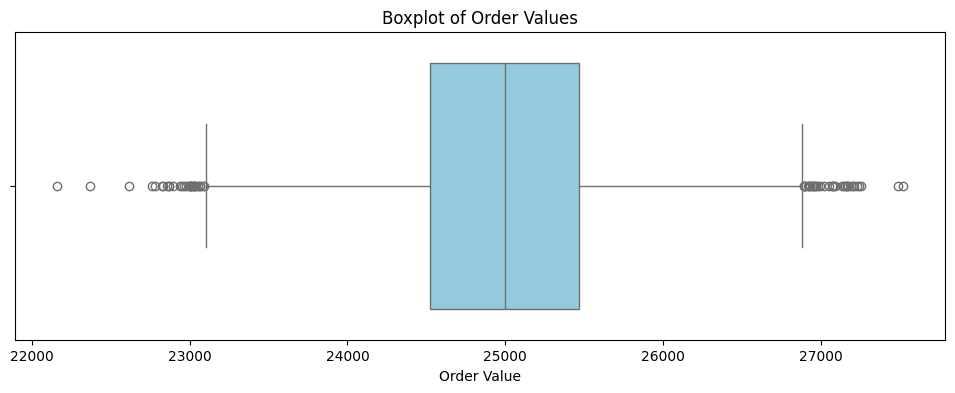

In [20]:
plt.figure(figsize=(12,4))

sns.boxplot(
    x = data['Order_Value'],
    color = 'skyblue'
)

plt.title("Boxplot of Order Values")
plt.xlabel("Order Value")


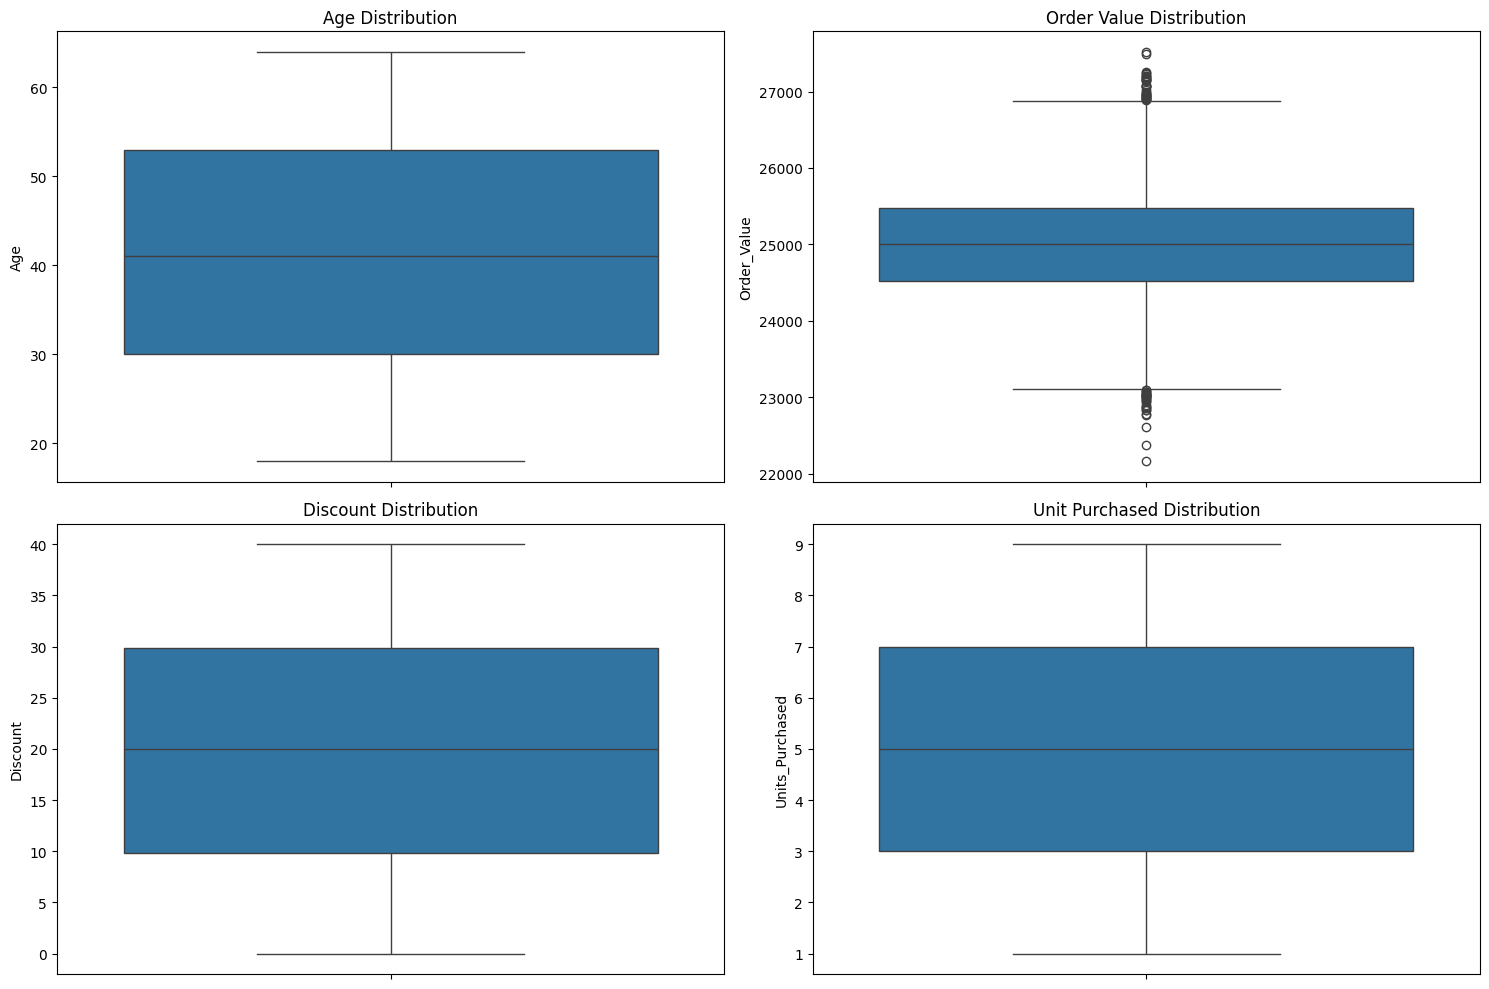

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(15,10))

sns.boxplot(data['Age'],ax=axes[0,0])
sns.boxplot(data['Order_Value'], ax=axes[0,1])
sns.boxplot(data['Discount'], ax=axes[1,0])
sns.boxplot(data['Units_Purchased'],ax=axes[1,1])

axes[0,0].set_title("Age Distribution")
axes[0,1].set_title('Order Value Distribution')
axes[1,0].set_title('Discount Distribution')
axes[1,1].set_title("Unit Purchased Distribution")

plt.tight_layout()
plt.show()

In [23]:
def interpret_boxplot(series,name):
  q1 = series.quantile(0.25)

  median = series.median()

  q3 = series.quantile(0.75)

  iqr = q3 - q1

  lower_fence = q1 - 1.5 * iqr
  upper_fence = q3 + 1.5 * iqr

  lower_outliers = (series < lower_fence).sum()
  upper_outliers = (series > upper_fence).sum()

  print("\nVariable:",name)
  print("Q1:",round(q1,2))
  print("Median:",round(median,2))
  print("Q3:",round(q3,2))
  print("IQR:",round(iqr,2))
  print("Lower Outliers:",lower_outliers)
  print("Upper Outliers:",upper_outliers)

for col in numerical_columns:
  interpret_boxplot(data[col],col)


Variable: Age
Q1: 30.0
Median: 41.0
Q3: 53.0
IQR: 23.0
Lower Outliers: 0
Upper Outliers: 0

Variable: Order_Value
Q1: 24521.26
Median: 24998.31
Q3: 25469.46
IQR: 948.19
Lower Outliers: 30
Upper Outliers: 35

Variable: Units_Purchased
Q1: 3.0
Median: 5.0
Q3: 7.0
IQR: 4.0
Lower Outliers: 0
Upper Outliers: 0

Variable: Discount
Q1: 9.87
Median: 19.98
Q3: 29.85
IQR: 19.98
Lower Outliers: 0
Upper Outliers: 0

Variable: Customer_Rating
Q1: 2.0
Median: 3.0
Q3: 4.0
IQR: 2.0
Lower Outliers: 0
Upper Outliers: 0


#SKEWNESS

In [25]:
for column in numerical_columns:
  skew = data[column].skew()
  print("\nVariable:",column)
  print("Skewness:",round(skew,3))

  if skew > 0.5:
    print("Interpretation: Positively Skewed")

  elif skew < -0.5:
    print("Interpretation: Negatively Skewed")

  else:
    print("Interpreattion Approximately Symmetric")


Variable: Age
Skewness: -0.0
Interpreattion Approximately Symmetric

Variable: Order_Value
Skewness: 0.023
Interpreattion Approximately Symmetric

Variable: Units_Purchased
Skewness: -0.019
Interpreattion Approximately Symmetric

Variable: Discount
Skewness: 0.009
Interpreattion Approximately Symmetric

Variable: Customer_Rating
Skewness: -0.001
Interpreattion Approximately Symmetric


Compare mean and median

In [26]:
for column in numerical_columns:
  mean = data[column].mean()
  median = data[column].median()
  print("\nVariable:",column)
  print("Mean:",round(mean,2))
  print("Median:",round(median,2))
  print("Difference:",round(mean - median, 2))


Variable: Age
Mean: 41.05
Median: 41.0
Difference: 0.05

Variable: Order_Value
Mean: 25000.2
Median: 24998.31
Difference: 1.89

Variable: Units_Purchased
Mean: 5.05
Median: 5.0
Difference: 0.05

Variable: Discount
Mean: 19.91
Median: 19.98
Difference: -0.07

Variable: Customer_Rating
Mean: 3.0
Median: 3.0
Difference: 0.0


In [27]:
category_statistics = data.groupby('Category')['Order_Value'].agg(
    ['count','mean','median','std','min','max']
)

display(category_statistics)

,count,mean,median,std,min,max
Category,,,,,,
Electronics,2508,25007.615853,25018.181863,720.311297,22613.723284,27519.626746
Fashion,2515,24992.409629,24973.983575,701.808486,22162.164941,27488.931991
Grocery,2484,25003.785815,25014.298256,679.324599,22826.776324,27251.214118
Home,2493,24997.041778,24993.246167,686.832672,22760.167606,27208.876514


Calculate IQR for each category

In [28]:
def calculate_iqr(group):
  q1 = group.quantile(0.25)
  q3 = group.quantile(0.75)

  iqr = q3 - q1

  return iqr

In [29]:
category_iqr = data.groupby('Category')['Order_Value'].apply(calculate_iqr)
display(category_iqr)

,Order_Value
Category,
Electronics,992.785189
Fashion,955.855654
Grocery,927.964263
Home,913.291471


Category-wise boxplot

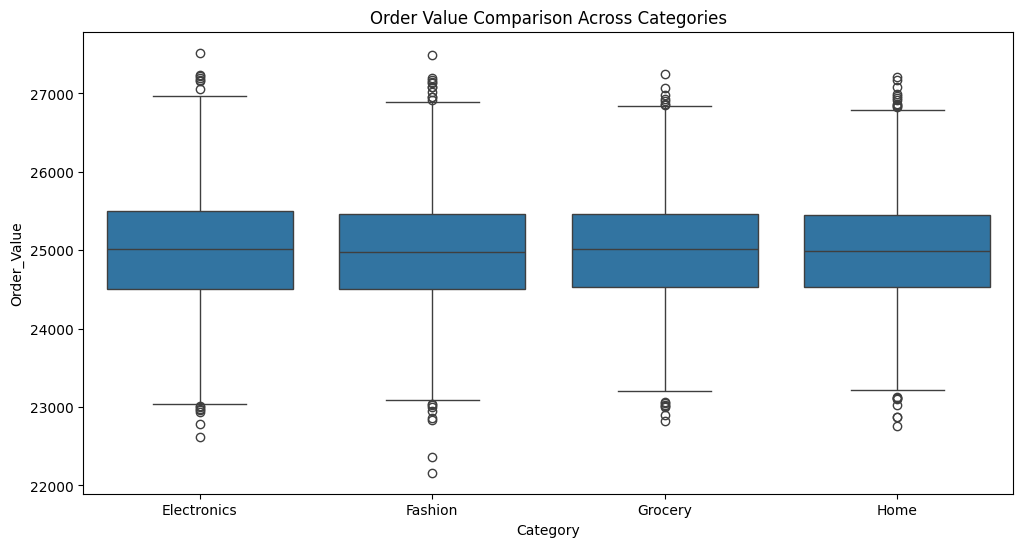

In [30]:
plt.figure(figsize=(12,6))

sns.boxplot(
    data=data,
    x='Category',
    y='Order_Value'
)

plt.title("Order Value Comparison Across Categories")

plt.show()